In [ ]:
%pip install pandas
import pandas as pd
raw_df = pd.read_csv("statisctics1_Mitochondria_Raw.tsv default  node.csv")

In [1]:
%pip install pandas requests py4cytoscape

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd, os

files = ["mitochondrion_annotations.txt"]      # add the manual and high-throughput files here
keep_methods = None    # None = keep everything; or e.g. ["manually curated", "high-throughput"]

ann = pd.concat([pd.read_csv(f, sep="\t", comment="!") for f in files if os.path.exists(f)],
                ignore_index=True)
ann.columns = ann.columns.str.strip()
ID, NAME = "Systematic Name/Complex Accession", "Gene/Complex"

ann = ann[~ann[ID].astype(str).str.startswith("CPX-")]                              # drop complexes
ann = ann[~ann["Qualifier"].astype(str).str.contains("NOT", case=False, na=False)]  # drop negatives
print(ann["Method"].value_counts())

if keep_methods:
    ann = ann[ann["Method"].isin(keep_methods)]

genes = (ann[[ID, NAME]].dropna(subset=[ID]).drop_duplicates(ID)
         .rename(columns={ID: "orf", NAME: "symbol"}))
genes["orf"] = genes["orf"].astype(str).str.strip()
genes["symbol"] = genes["symbol"].fillna(genes["orf"])
genes.to_csv("mito_genes.tsv", sep="\t", index=False)
print(len(genes), "unique genes")
assert len(genes) > 0, "Gene list is empty: check keep_methods against the labels printed above"

Method
computational    1959
Name: count, dtype: int64
597 unique genes


In [3]:
import requests
try:
    r = requests.get("https://string-db.org/api/json/version", timeout=30)
    print(r.status_code, r.text)
except Exception as e:
    print("CANNOT REACH STRING:", type(e).__name__, e)

200 [{"string_version": "12.5", "stable_address": "https://version-12-5.string-db.org"}]


In [4]:
import io, time

def string_post(method, **params):
    params.update(species=4932, caller_identity="mito_ppi_project")
    r = requests.post(f"https://string-db.org/api/tsv/{method}", data=params, timeout=300)
    if not r.ok:
        raise RuntimeError(f"STRING {method} failed ({r.status_code}): {r.text[:300]}")
    return pd.read_csv(io.StringIO(r.text), sep="\t")

mapped = string_post("get_string_ids", identifiers="\r".join(genes["orf"]), echo_query=1)
print(len(mapped), "of", len(genes), "genes recognised")
time.sleep(1)

raw = string_post("network", identifiers="\r".join(mapped["stringId"]),
                  required_score=700, network_type="physical").drop_duplicates()

edges = pd.DataFrame({
    "source": raw["stringId_A"].str.replace("4932.", "", regex=False),
    "target": raw["stringId_B"].str.replace("4932.", "", regex=False),
    "score":  raw["score"]})
edges.to_csv("mito_ppi_edges.tsv", sep="\t", index=False)
print(len(edges), "interactions")

597 of 597 genes recognised
3580 interactions


In [5]:
%pip install py4cytoscape
import py4cytoscape as p4c
p4c.cytoscape_ping()        # must print "You are connected to Cytoscape!"

edges["interaction"] = "pp"
in_net = set(edges["source"]) | set(edges["target"])
nodes = genes[genes["orf"].isin(in_net)].rename(columns={"orf": "id"})

p4c.create_network_from_data_frames(nodes=nodes, edges=edges,
                                    title="Yeast mitochondrial PPI",
                                    collection="SGD GO:0005739")
p4c.set_node_label_mapping("symbol")
p4c.layout_network("force-directed")
p4c.save_session("mito_ppi.cys")
print(len(nodes), "proteins,", len(edges), "interactions")

Note: you may need to restart the kernel to use updated packages.
You are connected to Cytoscape!
Applying default style...
Applying preferred layout
style_name not specified, so updating "default" style.
This file has been overwritten.
341 proteins, 3580 interactions


Just checking the amount of interaction according to confidence score and the type 

In [6]:
for ntype in ["functional", "physical"]:
    for score in [400, 700]:
        n = len(string_post("network", identifiers="\r".join(mapped["stringId"]),
                            required_score=score, network_type=ntype).drop_duplicates())
        print(f"{ntype:10s} score>={score}: {n} interactions")
        time.sleep(1)

functional score>=400: 12106 interactions
functional score>=700: 5955 interactions
physical   score>=400: 5083 interactions
physical   score>=700: 3580 interactions


nodes                                     341.0000
edges                                    3580.0000
average degree                             20.9971
density                                     0.0618
connected components                       30.0000
largest component (nodes)                 263.0000
average clustering coefficient              0.4856
transitivity                                0.9438
average shortest path (largest comp.)       4.4455
diameter (largest comp.)                   13.0000
degree assortativity                        0.8561
dtype: float64
          id  degree  betweenness  closeness  clustering  symbol
115  YNL284C      82     0.007237   0.224576    0.880759  MRPL10
113  YLR439W      82     0.009475   0.224826    0.880759   MRPL4
50   YHL004W      82     0.059100   0.239211    0.887082    MRP4
101  YGR220C      82     0.007237   0.224576    0.880759   MRPL9
98   YNL177C      82     0.062485   0.238646    0.880458  MRPL22
32   YDR347W      81     0.004338 

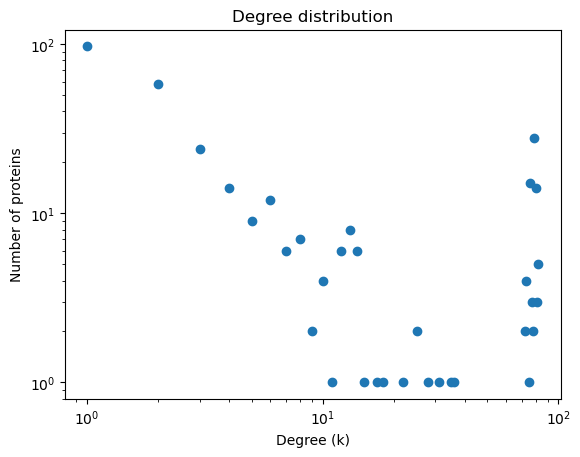

In [7]:
import networkx as nx, matplotlib.pyplot as plt

G = nx.from_pandas_edgelist(edges, "source", "target", edge_attr="score")
G.remove_edges_from(nx.selfloop_edges(G))
comps = sorted(nx.connected_components(G), key=len, reverse=True)
GC = G.subgraph(comps[0])                     # largest connected component

summary = {
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "average degree": 2 * G.number_of_edges() / G.number_of_nodes(),
    "density": nx.density(G),
    "connected components": len(comps),
    "largest component (nodes)": len(GC),
    "average clustering coefficient": nx.average_clustering(G),
    "transitivity": nx.transitivity(G),
    "average shortest path (largest comp.)": nx.average_shortest_path_length(GC),
    "diameter (largest comp.)": nx.diameter(GC),
    "degree assortativity": nx.degree_assortativity_coefficient(G),
}
pd.Series(summary).round(4).to_csv("network_summary.tsv", sep="\t", header=False)
print(pd.Series(summary).round(4))

# Per-protein table
node_stats = pd.DataFrame({
    "degree": dict(G.degree()),
    "betweenness": nx.betweenness_centrality(G),
    "closeness": nx.closeness_centrality(G),
    "clustering": nx.clustering(G),
}).rename_axis("id").reset_index()
node_stats = node_stats.merge(genes.rename(columns={"orf": "id"}), on="id", how="left")
node_stats.sort_values("degree", ascending=False).to_csv("node_metrics.tsv", sep="\t", index=False)
print(node_stats.sort_values("degree", ascending=False).head(10))    # top hubs

# Degree distribution
node_stats["degree"].value_counts().sort_index().plot(style="o", loglog=True)
plt.xlabel("Degree (k)"); plt.ylabel("Number of proteins"); plt.title("Degree distribution")
plt.savefig("degree_distribution.png", dpi=200, bbox_inches="tight")

In [8]:
p4c.load_table_data(node_stats, data_key_column="id", table_key_column="name")
p4c.set_node_size_mapping("degree", [1, 20, 80], [20, 50, 100])

style_name not specified, so updating "default" style.
style_name not specified, so updating "default" style.


''

In [9]:
core = nx.k_core(G)                           # densest core of the network
sym = genes.set_index("orf")["symbol"]
print(len(core), "proteins and", core.number_of_edges(), "edges in the densest core")
print(sorted(sym.reindex(list(core)).tolist()))

print("median degree, whole network:", node_stats["degree"].median())

rest = G.copy()
rest.remove_nodes_from(list(core.nodes))
rest.remove_nodes_from(list(nx.isolates(rest)))
print("\nWithout the core:", rest.number_of_nodes(), "proteins,", rest.number_of_edges(), "edges")
print("average clustering:", round(nx.average_clustering(rest), 4))
print("transitivity:", round(nx.transitivity(rest), 4))
print("assortativity:", round(nx.degree_assortativity_coefficient(rest), 4))

# Bottleneck proteins: more informative than degree here
print(node_stats.sort_values("betweenness", ascending=False)
      .head(15)[["symbol", "degree", "betweenness"]])


74 proteins and 2701 edges in the densest core
['AEP1', 'AEP2', 'ATP25', 'EHD3', 'FYV4', 'IMG1', 'IMG2', 'MHR1', 'MRP1', 'MRP10', 'MRP13', 'MRP17', 'MRP2', 'MRP20', 'MRP21', 'MRP35', 'MRP4', 'MRP51', 'MRP7', 'MRPL10', 'MRPL13', 'MRPL15', 'MRPL16', 'MRPL17', 'MRPL20', 'MRPL22', 'MRPL23', 'MRPL24', 'MRPL25', 'MRPL27', 'MRPL28', 'MRPL3', 'MRPL31', 'MRPL32', 'MRPL33', 'MRPL35', 'MRPL36', 'MRPL38', 'MRPL39', 'MRPL4', 'MRPL40', 'MRPL49', 'MRPL50', 'MRPL51', 'MRPL6', 'MRPL7', 'MRPL8', 'MRPL9', 'MRPS12', 'MRPS16', 'MRPS17', 'MRPS18', 'MRPS28', 'MRPS35', 'MRPS5', 'MRPS8', 'MRPS9', 'MRX14', 'NAM9', 'PET123', 'QRI5', 'RML2', 'RSM10', 'RSM18', 'RSM19', 'RSM23', 'RSM24', 'RSM25', 'RSM26', 'RSM27', 'RSM7', 'RTC6', 'SWS2', 'YML6']
median degree, whole network: 3.0

Without the core: 259 proteins, 475 edges
average clustering: 0.3436
transitivity: 0.6184
assortativity: 0.5125
     symbol  degree  betweenness
167    SSC1      17     0.146297
230   UTP10       6     0.131054
28    RSM24      80     0.10

Intact network: 341 proteins, 3580 interactions
  running static degree attack ...
  running static betweenness attack ...
  running static closeness attack ...
  running 100 random-failure runs ...

=== SUMMARY (lower R = more damaging attack) ===
                  R_lcc R_efficiency f_half_lcc f_half_efficiency largest_single_drop caused_by at_step  R_lcc_z_vs_random  R_lcc_p_vs_random  R_efficiency_z_vs_random  R_efficiency_p_vs_random
degree         0.184562     0.144825    0.26393          0.117302                  29      ACP1      90            -4.6182             0.0099                   -6.4436                    0.0099
betweenness    0.119366     0.124193   0.064516          0.055718                  68      COX1      22            -7.6079             0.0099                   -7.5942                    0.0099
closeness      0.169426     0.122514   0.249267          0.099707                  47      VAR1      43            -5.3123             0.0099                   -7.6879  

In commands_post(): unrecognized (table entry): Yeast mitochondrial PPI_2  (table name): USER



Cytoscape step skipped (is Cytoscape open?): CyError In commands_post(): unrecognized (table entry): Yeast mitochondrial PPI_2  (table name): USER
You can import attack_static/node_attack_table.tsv by hand: File > Import > Table from File.

Done. Tables and figures are in the 'attack_static' folder.


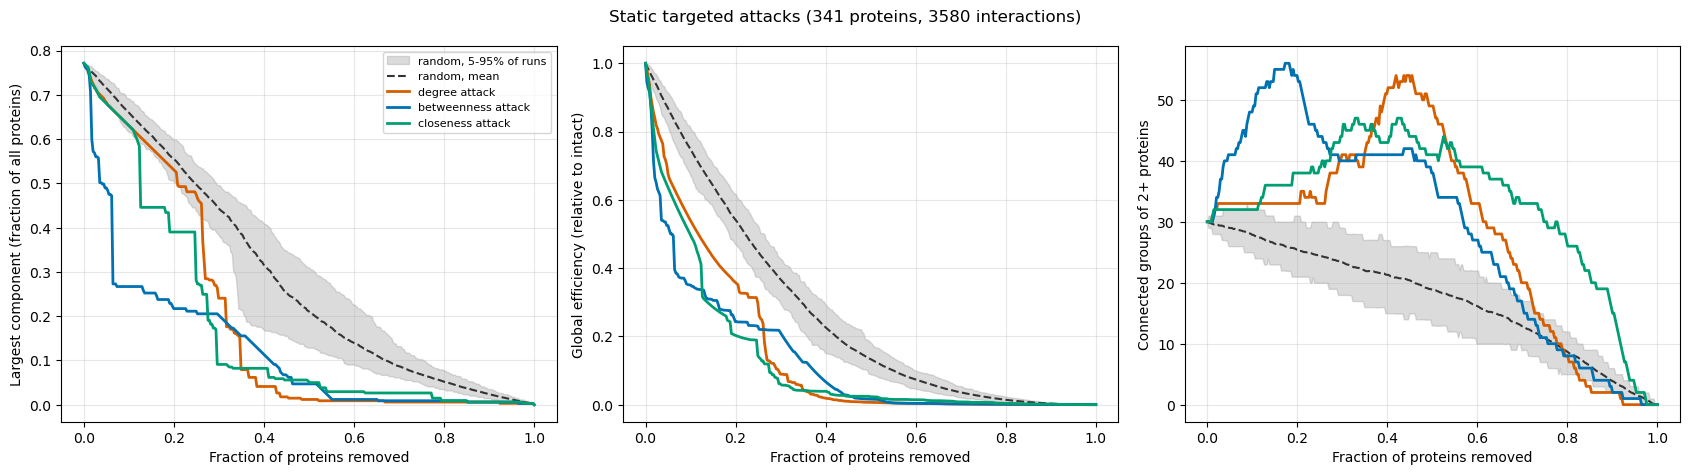

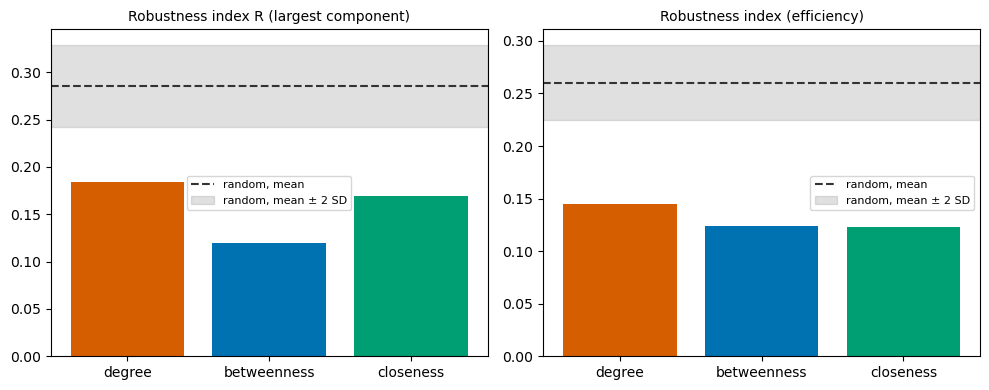

In [10]:
%run static_attack.py


=== DEGREE attack: most damaging removal is step 90, ACP1 ===
Largest component: 155 -> 126 proteins
Pieces that split off: [24, 2, 1, 1]
Removed before it (89): MRPL9, MRP4, MRPL4, MRPL22, MRPL10, MRPL36, MRP1, MRPL39, MRPL16, MRPS5, MRPL27, IMG1, IMG2, RSM24, MRP20, RSM18, MRP13, RSM26, YML6, MRPL33, MRP7, MRPL23, MRP21, MRPS9, MRPL32, MRP10, RSM10, MRPS28, RML2, RSM23, MRPS35, RSM27, FYV4, RSM25, MRPL8, RSM7, MRP17, MRPL3, MRPS8, MRPS17, SWS2, NAM9, MRPL17, MRPS18, MRPS12, RSM19, MRPS16, MRP51, MRPL51, MRP2, MRX14, MHR1, MRPL28, MRPL24, PET123, EHD3, MRPL7, MRPL35, MRPL25, MRPL6, MRPL49, MRPL31, MRPL38, MRPL13, MRPL20, QRI5, MRPL15, MRPL50, MRPL40, RTC6, MRP35, RSM28, AEP1, ATP25, AEP2, MRPL11, MRPL19, VAR1, RSM22, CCM1, MRP49, MRPL37, MNP1, MRPL1, ATP2, SSC1, COX1, ATP3, ATP5
Piece 1 (24): ARH1, ECM10, GRX5, GTF1, HEM15, HER2, ISD11, JAC1, MSD1, NFS1, PAM16, PET112, SDH1, SDH5, SDH6, SDH7, SDH8, SDH9, SSQ1, TAH18, TIM21, YAH1, YDR061W, YFH1
Piece 2 (2): ATP12, FMC1
Piece 3 (1): CE

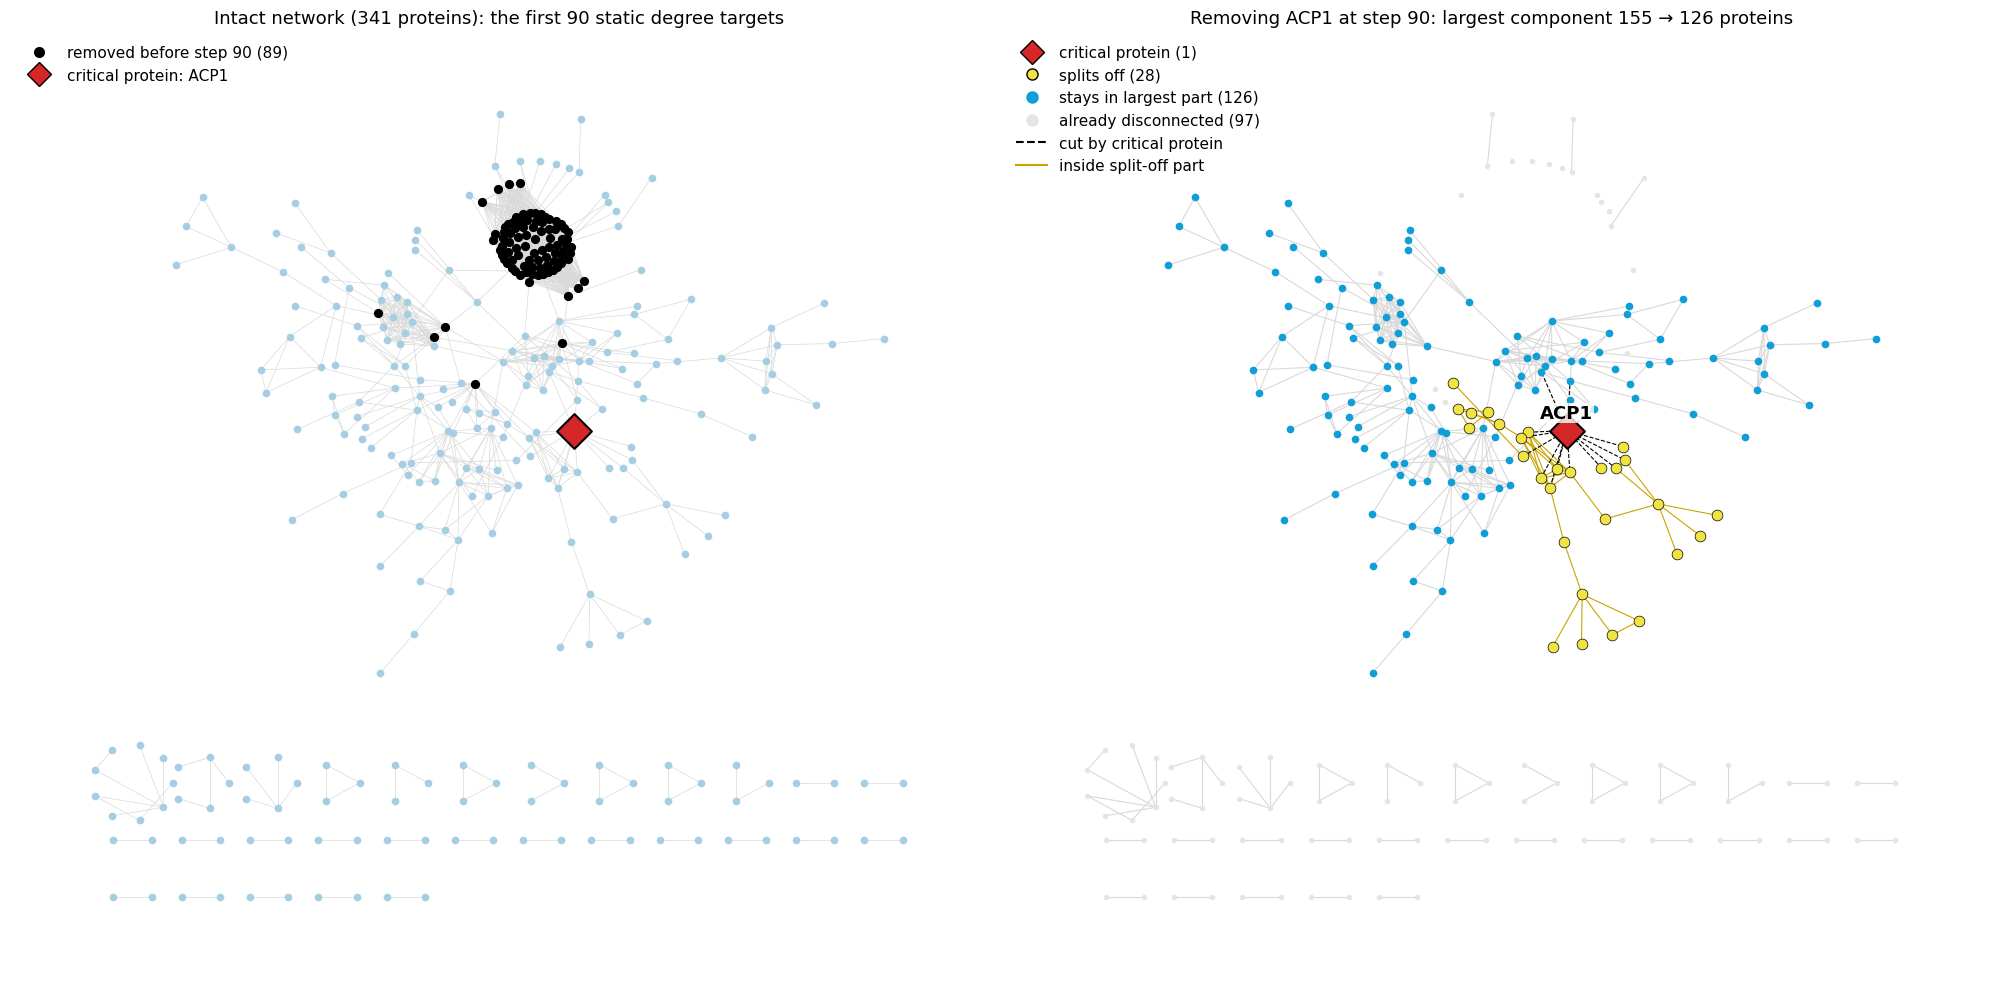

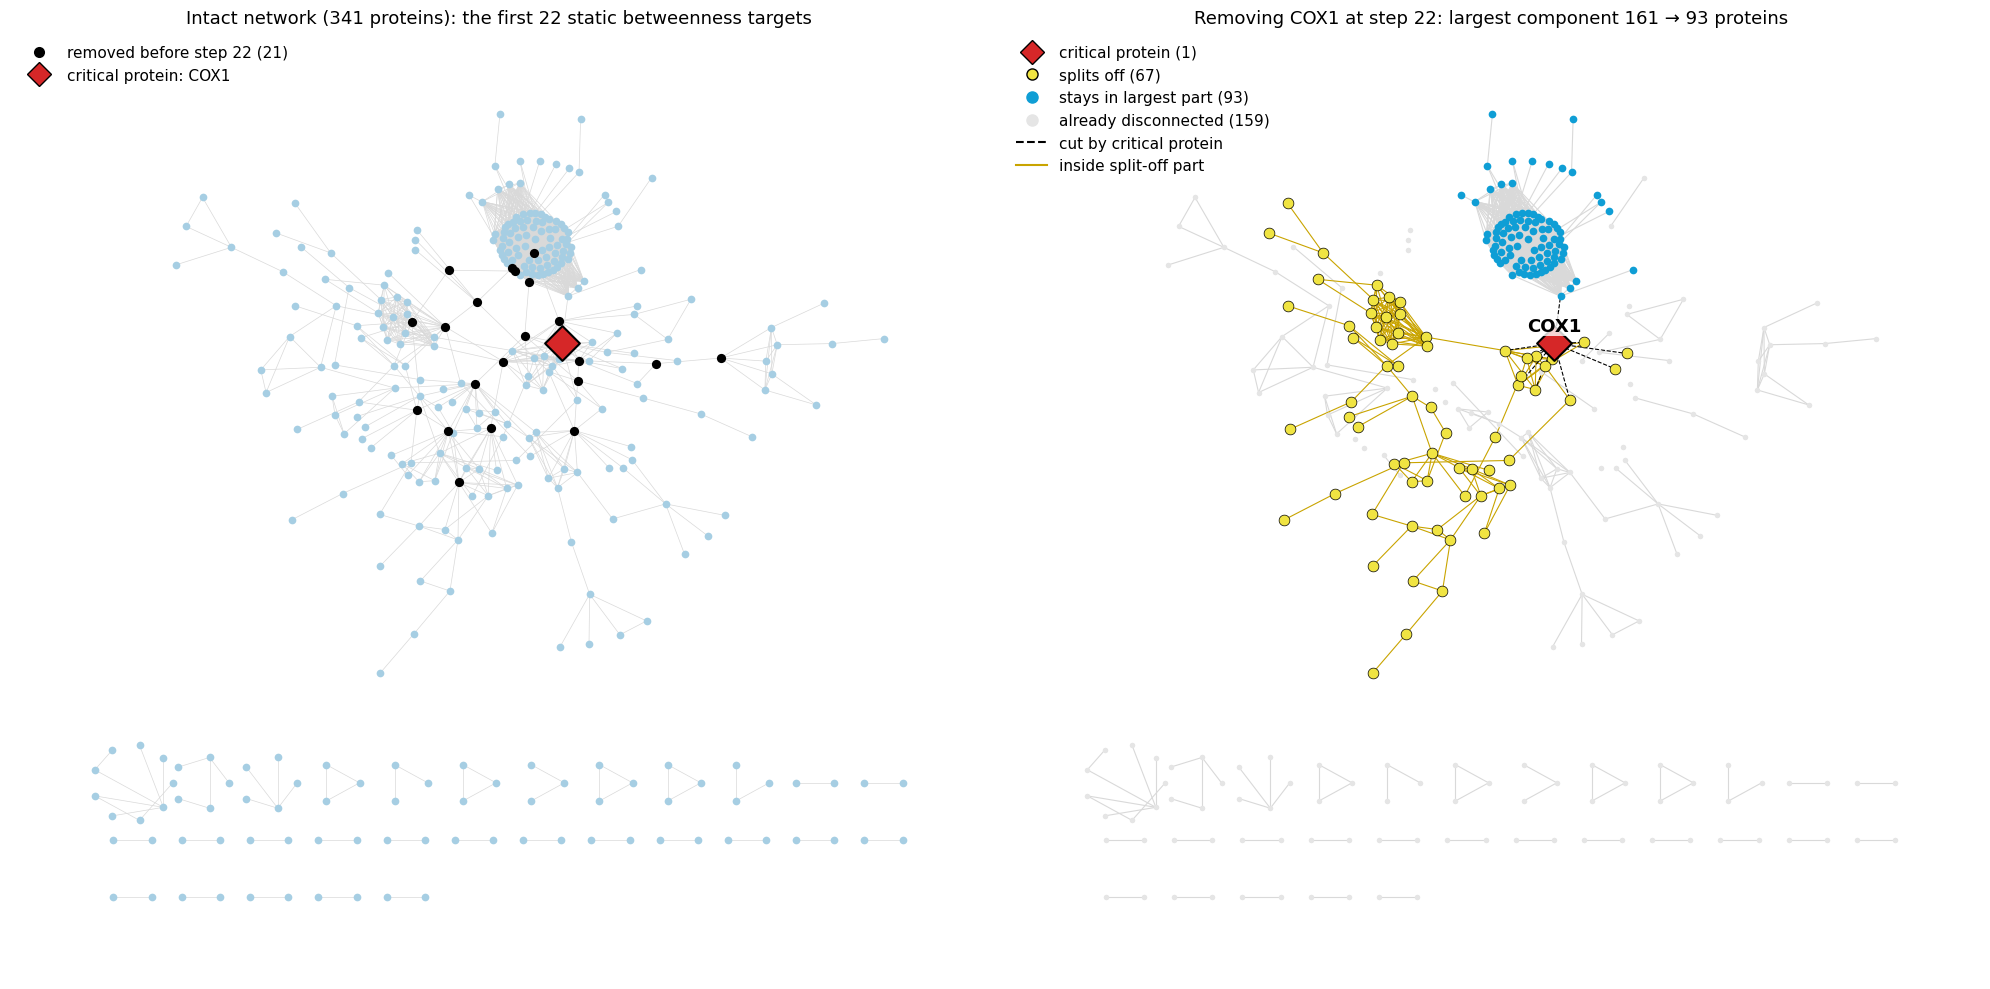

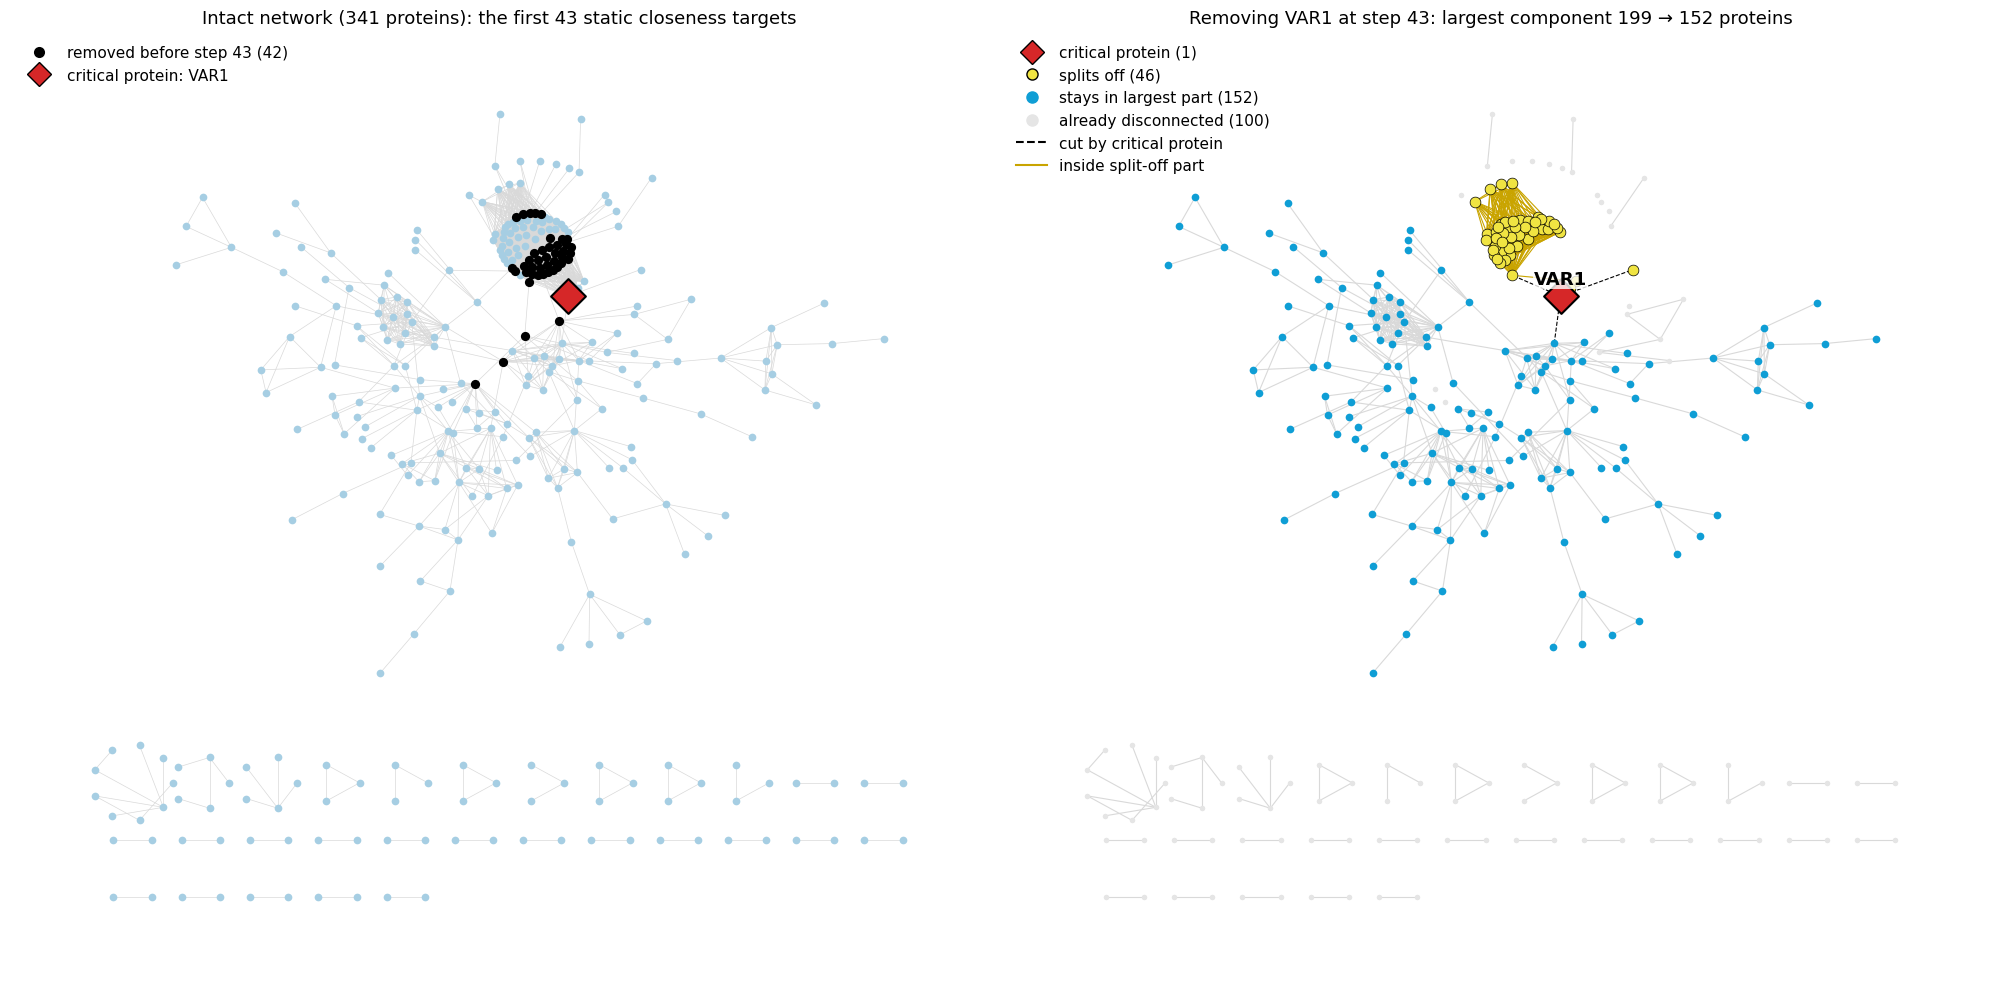

In [11]:
%run attack_views.py

Intact network: 341 proteins, 3580 interactions
  static degree attack ...
  static betweenness attack ...
  static closeness attack ...
  adaptive degree attack ...
    degree: 50/341 removed
    degree: 100/341 removed
    degree: 150/341 removed
    degree: 200/341 removed
    degree: 250/341 removed
    degree: 300/341 removed
  adaptive betweenness attack ...
    betweenness: 50/341 removed
    betweenness: 100/341 removed
    betweenness: 150/341 removed
    betweenness: 200/341 removed
    betweenness: 250/341 removed
    betweenness: 300/341 removed
  adaptive closeness attack ...
    closeness: 50/341 removed
    closeness: 100/341 removed
    closeness: 150/341 removed
    closeness: 200/341 removed
    closeness: 250/341 removed
    closeness: 300/341 removed
  100 random-failure runs ...

=== SUMMARY (lower R = more damaging) ===
                         R_lcc R_efficiency f_half_lcc f_half_efficiency largest_single_drop caused_by at_step  R_lcc_z_vs_random  R_lcc_p_vs_rand

OSError: [Errno 22] Invalid argument: 'attack_adaptive/split_adaptive_closeness.png'

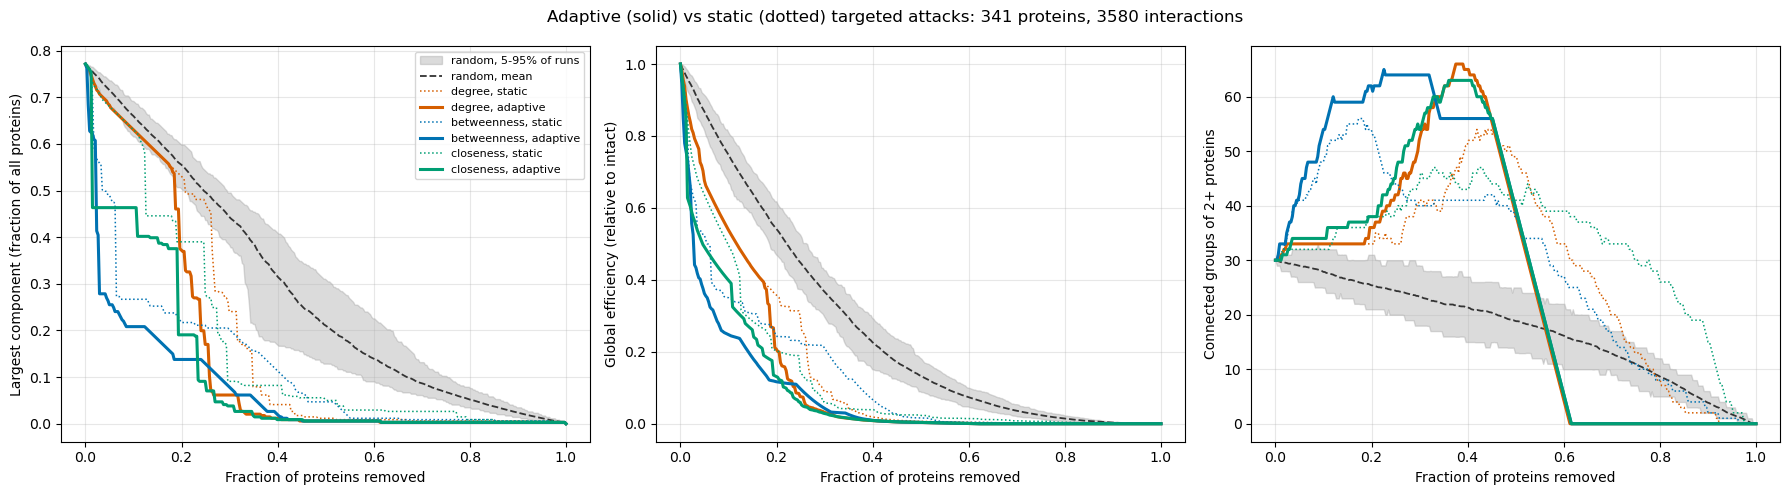

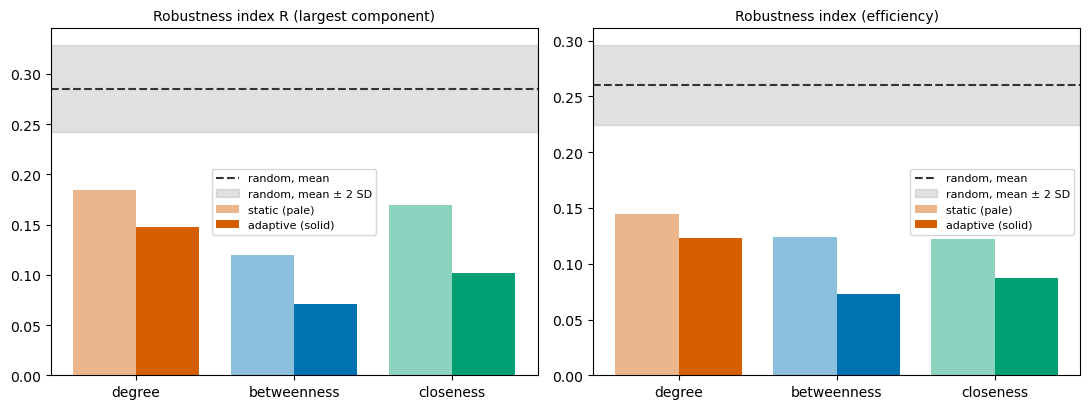

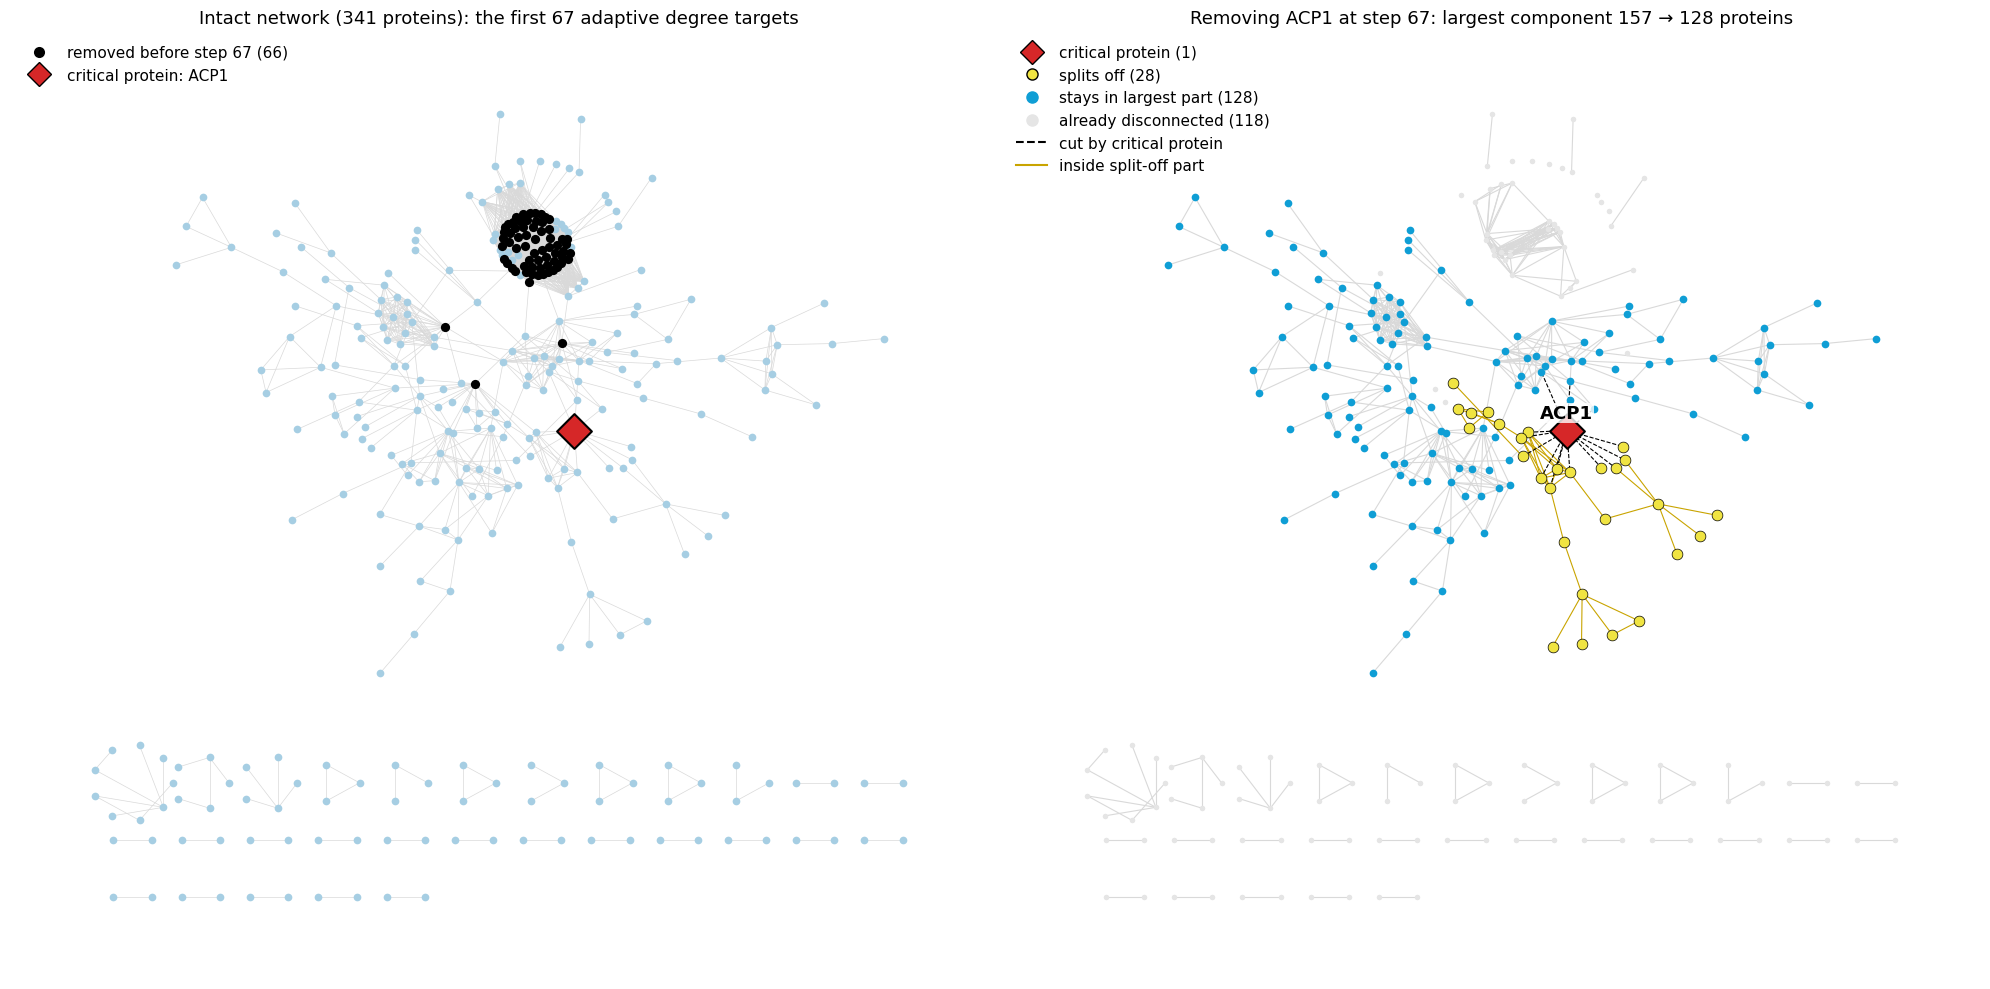

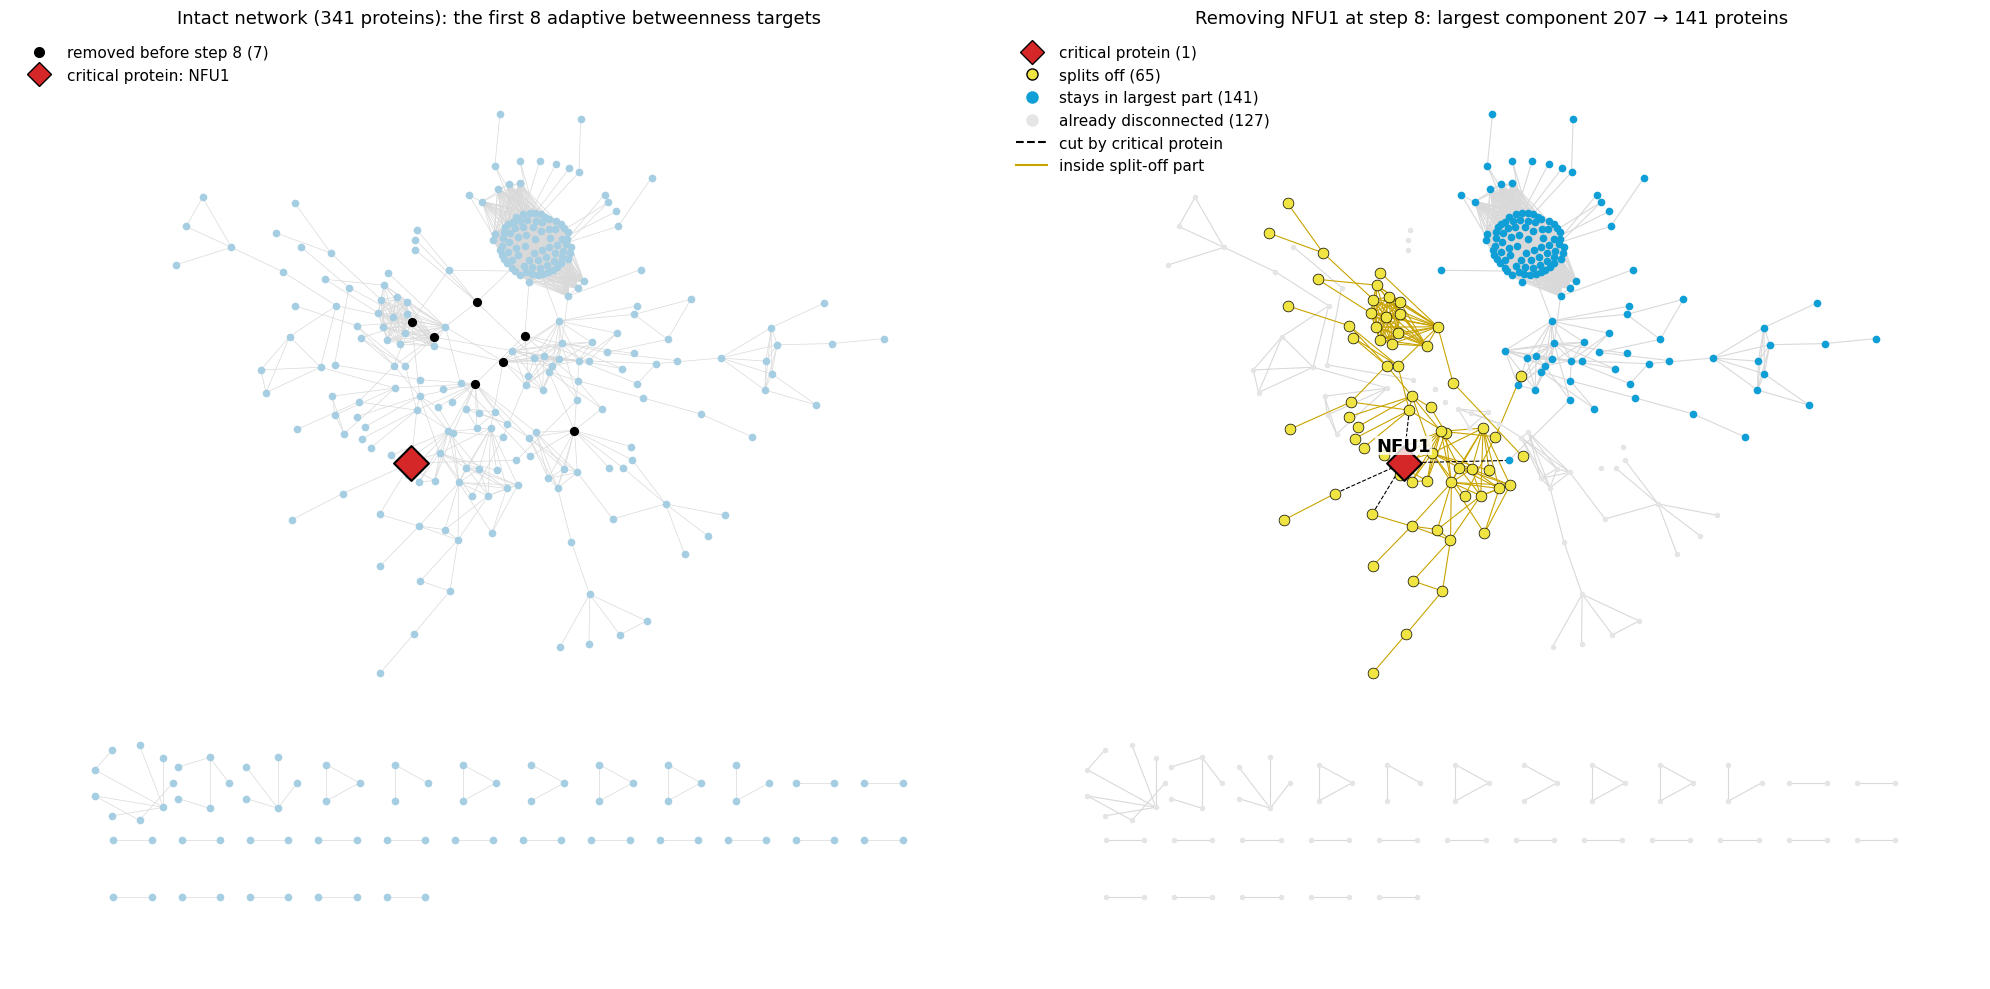

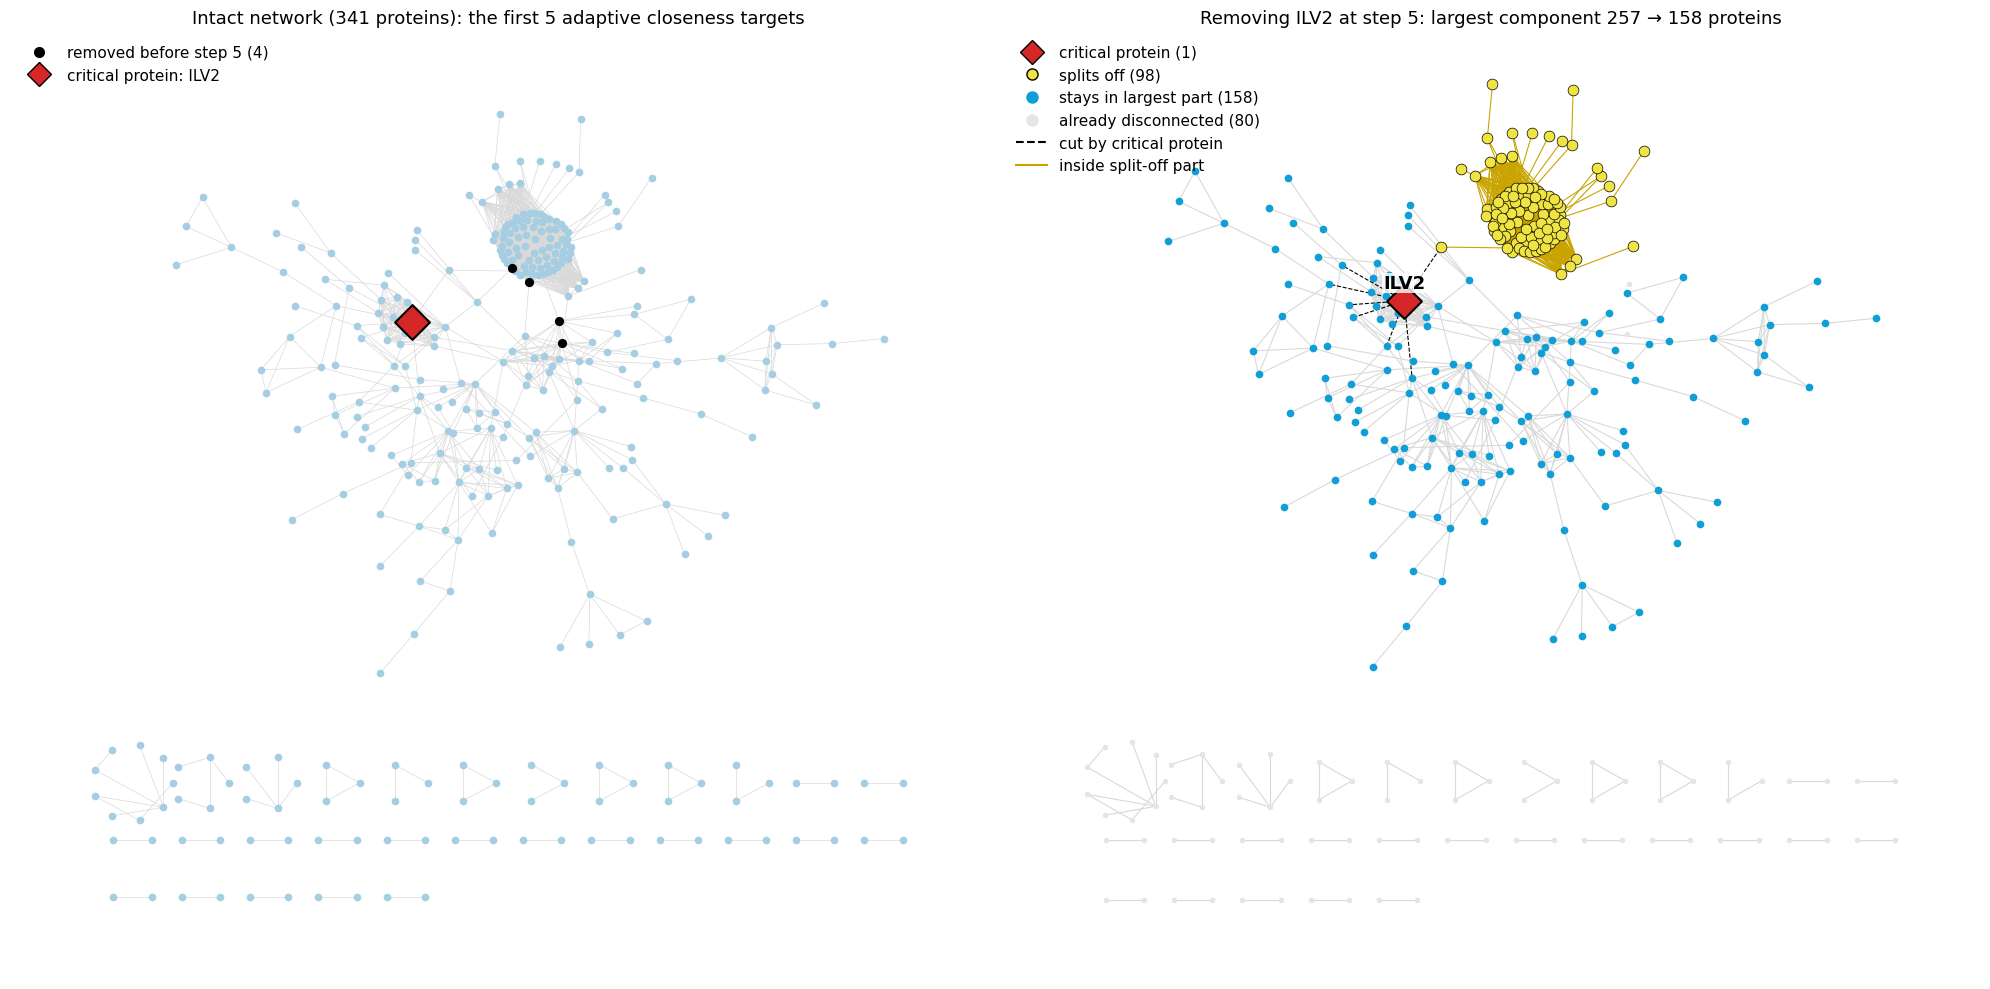

In [12]:
%run adaptive_attack

Intact network: 341 proteins, 3580 interactions
Running 500 random-failure runs ...
  50/500 runs done
  100/500 runs done
  150/500 runs done
  200/500 runs done
  250/500 runs done
  300/500 runs done
  350/500 runs done
  400/500 runs done
  450/500 runs done
  500/500 runs done
Targeted attacks read from attack_adaptive/adaptive_curves.tsv

=== RANDOM FAILURE: distribution over 500 runs ===
                        mean  ci95_low  ci95_high      std  cv_percent   median      p05      p95     min      max
R_lcc                 0.2829    0.2809     0.2849   0.0230      8.1428   0.2854   0.2438   0.3179  0.2049   0.3391
R_efficiency          0.2582    0.2565     0.2598   0.0189      7.3097   0.2580   0.2287   0.2885  0.1988   0.3176
f_half_lcc            0.3538    0.3496     0.3581   0.0484     13.6876   0.3578   0.2726   0.4223  0.1642   0.4633
f_half_efficiency     0.2195    0.2172     0.2218   0.0264     12.0344   0.2199   0.1760   0.2639  0.1232   0.2933
largest_single_drop  36.208

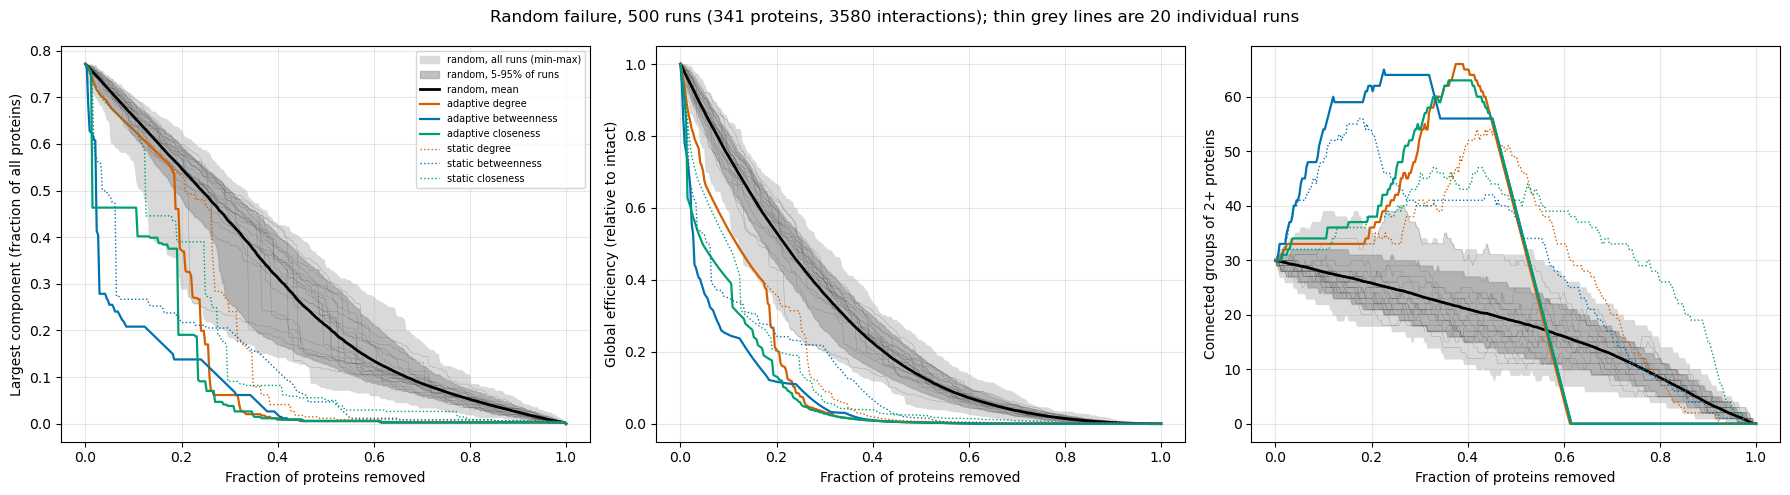

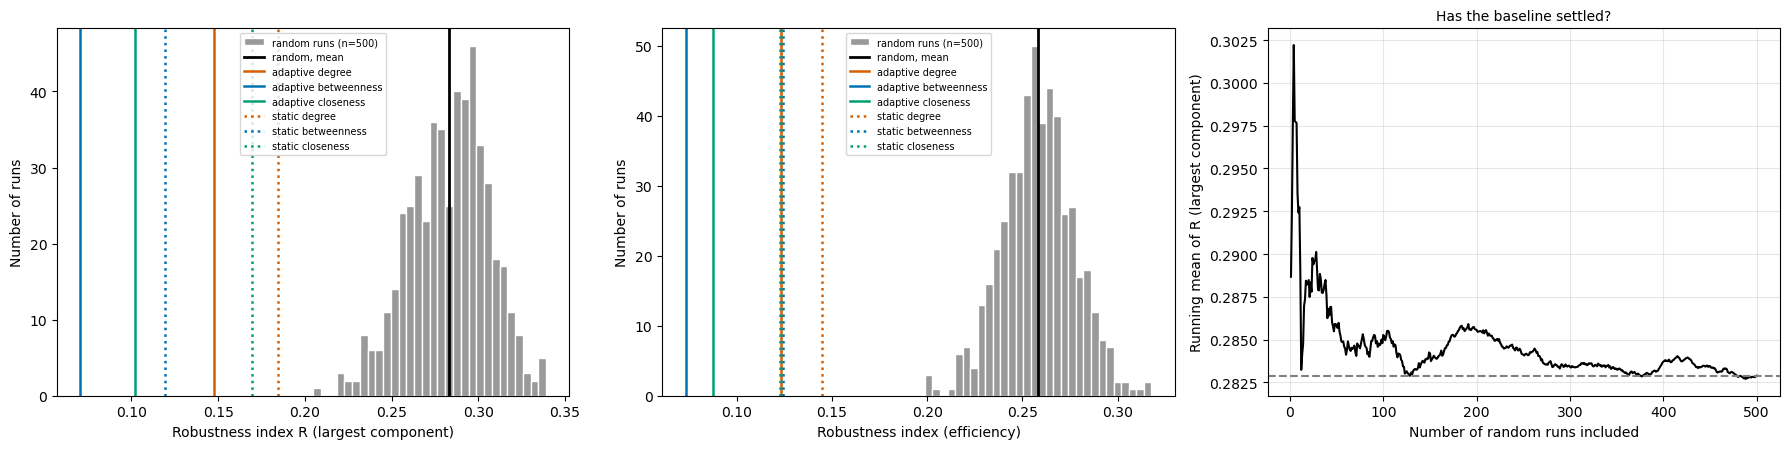

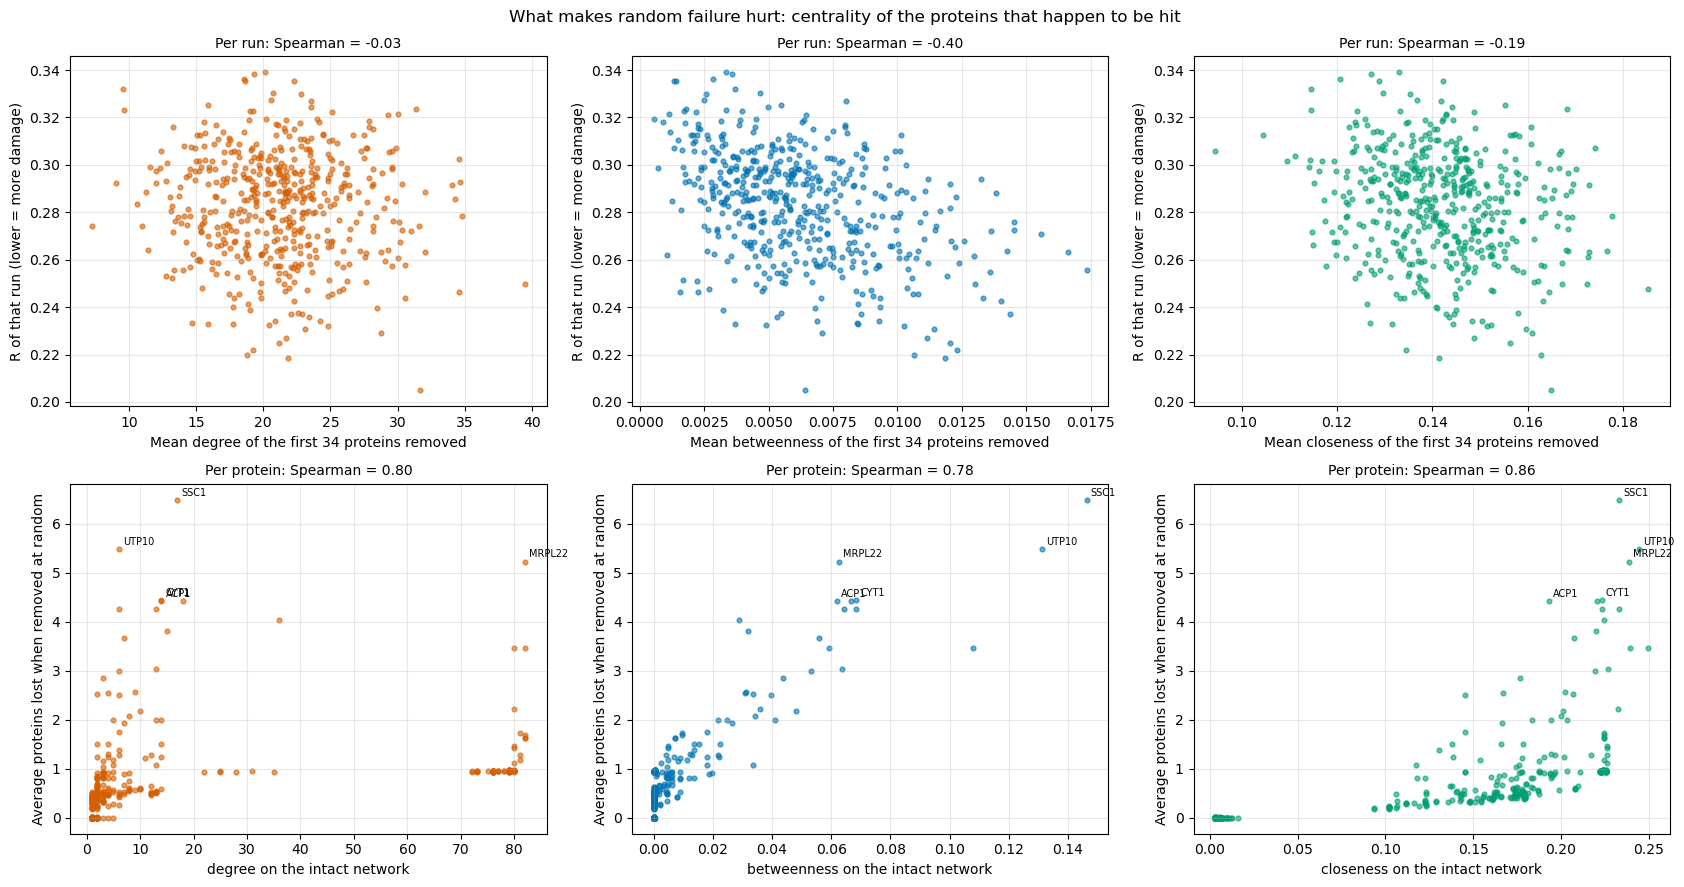

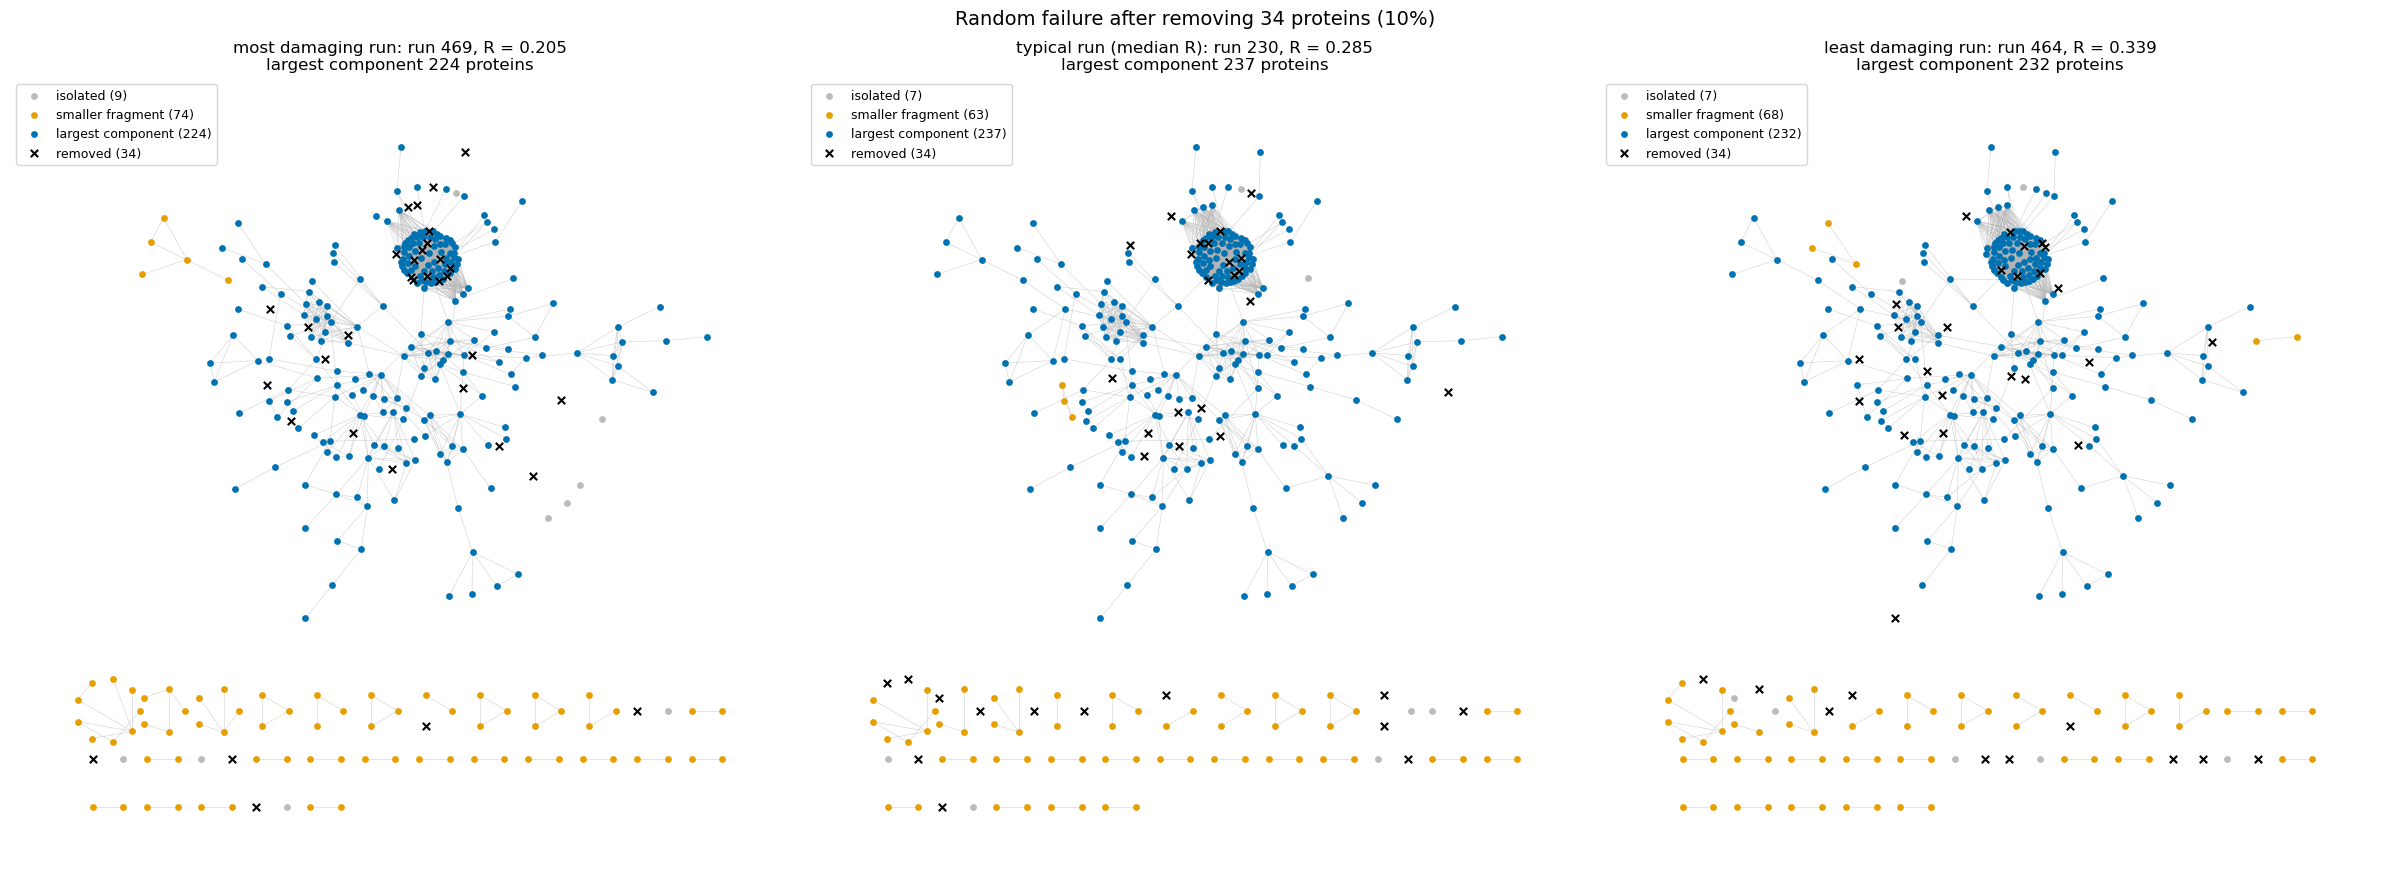

In [13]:
%run random_failure.py

Intact network: 341 proteins, largest component 263, 30 connected groups
Running 1000 random runs, measured at 7 removal levels ...
  200/1000 runs done
  400/1000 runs done
  600/1000 runs done
  800/1000 runs done
  1000/1000 runs done

=== RANDOM FAILURE at fixed removal levels (1000 runs) ===
lcc = largest component, as % of the intact largest component
                  proteins_removed  lcc_mean_%  lcc_sd  lcc_p05_%  lcc_p95_%  expected_if_no_fragmentation_%  survivors_in_lcc_%  efficiency_mean_%  efficiency_sd  components_mean  isolated_mean  extra_loss_from_fragmentation_%
fraction_removed                                                                                                                                                                                                                   
0.10                            34       85.35    3.20      80.23      89.35                            90.0               73.12              74.42           4.09            27.95     

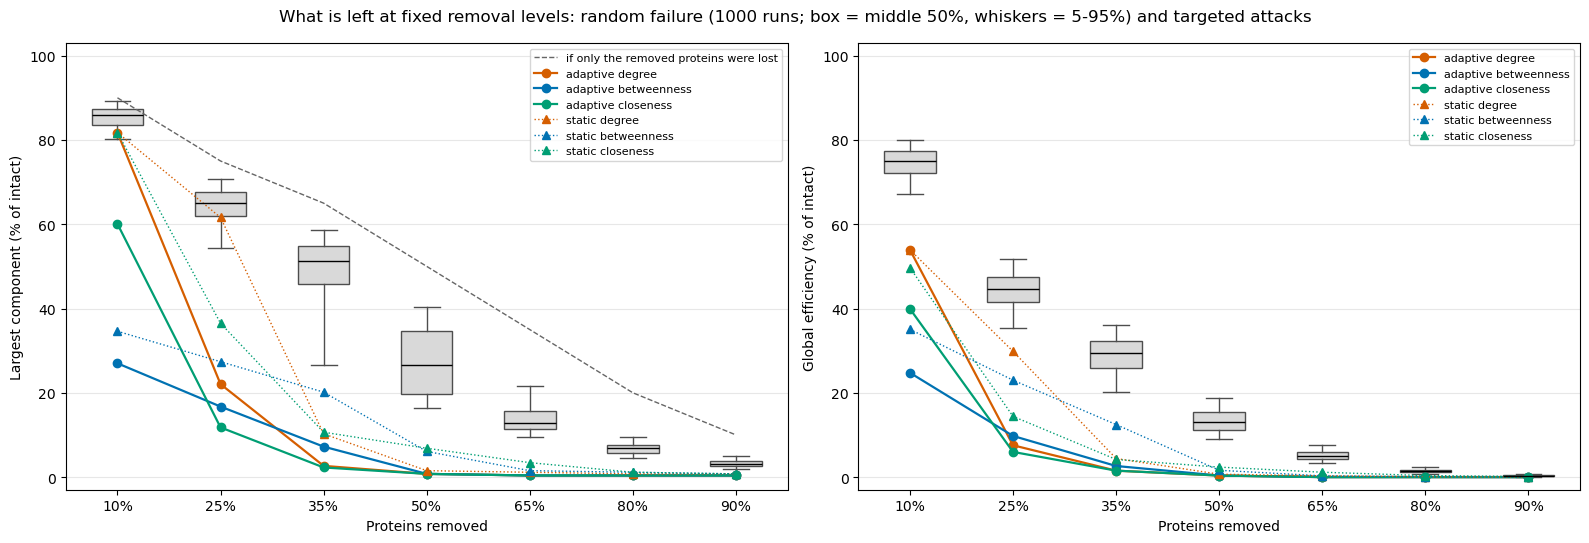

In [14]:
%run random_fractions.py